In [1]:
%matplotlib inline

import copy
import numpy as np
from astropy.io import fits
from aspired import spectral_reduction
from matplotlib import pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

# Line list
atlas_Hg_red = [5460.7348, 5769.5982, 5790.6630]
atlas_Ar_red = [
    6965.4307, 7067.2175, 7147.0416, 7272.9359, 7383.9805, 7503.8691,
    7635.1056, 7723.7599, 7948.1764, 8014.7857, 8115.3108, 8264.5225,
    8424.6475, 8521.4422, 8667.944, 9122.9674, 9224.4992, 9354.220, 9657.7863,
    9784.503
]
element_Hg_red = ['Hg'] * len(atlas_Hg_red)
element_Ar_red = ['Ar'] * len(atlas_Ar_red)

atlas_Ar_blue = [4158.590, 4200.674, 4272.169, 4300.101, 4510.733]
atlas_Hg_blue = [
    3650.153, 4046.563, 4077.8314, 4358.328, 5460.7348, 5769.598, 5790.663
]
atlas_Zn_blue = [4722.1569]
element_Hg_blue = ['Hg'] * len(atlas_Hg_blue)
element_Ar_blue = ['Ar'] * len(atlas_Ar_blue)
element_Zn_blue = ['Zn'] * len(atlas_Zn_blue)

# Set the frame
red_spatial_mask = np.arange(0, 330)
blue_spatial_mask = np.arange(335, 512)
red_spec_mask = np.arange(0, 1800)
blue_spec_mask = np.arange(500, 2060)

standard_name = 'l74546a'
standard_library = 'irafredcal'

/home/marco/git/aspired/src/aspired/__init__.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/marco/anaconda3/envs/python312/lib/python3.12/site-packages/rascal/calibrator.py:9: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


In [2]:
def extract_floyds(light_fits,
                   flat_fits,
                   arc_fits,
                   coeff_red=None,
                   coeff_blue=None,
                   renderer='default'):
    light_data = light_fits.data
    light_header = fits.Header(light_fits.header)

    red = spectral_reduction.TwoDSpec(light_data,
                                      header=light_header,
                                      spatial_mask=red_spatial_mask,
                                      spec_mask=red_spec_mask,
                                      cosmicray=True,
                                      sigclip=2.,
                                      readnoise=3.5,
                                      gain=2.3,
                                      log_level='INFO',
                                      log_file_name=None)

    blue = spectral_reduction.TwoDSpec(light_data,
                                       header=light_header,
                                       spatial_mask=blue_spatial_mask,
                                       spec_mask=blue_spec_mask,
                                       cosmicray=True,
                                       sigclip=2.,
                                       readnoise=3.5,
                                       gain=2.3,
                                       log_level='INFO',
                                       log_file_name=None)

    # Add the arcs before rectifying the image, which will apply the
    # rectification to the arc frames too
    blue.add_arc(arc_fits.data, fits.Header(arc_fits.header))
    blue.apply_mask_to_arc()
    red.add_arc(arc_fits.data, fits.Header(arc_fits.header))
    red.apply_mask_to_arc()

    # Get the trace to rectify the image
    red.ap_trace(nspec=1,
                 ap_faint=20,
                 percentile=10,
                 trace_width=50,
                 shift_tol=35,
                 fit_deg=5,
                 display=False)
    red.get_rectification(upsample_factor=5, coeff=coeff_red, display=True, renderer=renderer)
    red.apply_rectification()
    # Need to store the traces for fringe correction before overwriting them
    # with the new traces
    trace_red = copy.deepcopy(red.spectrum_list[0].trace)
    trace_sigma_red = copy.deepcopy(red.spectrum_list[0].trace_sigma)

    # Get the trace again for the rectified image and then extract
    red.ap_trace(nspec=1,
                 ap_faint=20,
                 percentile=10,
                 trace_width=25,
                 fit_deg=0,
                 display=False)
    red.ap_extract(apwidth=10, model='lowess', spec_id=0, display=True)

    # Do the same with the blue
    blue.ap_trace(nspec=1,
                  ap_faint=10,
                  percentile=10,
                  trace_width=20,
                  shift_tol=50,
                  fit_deg=5,
                  display=False)
    blue.get_rectification(upsample_factor=5, coeff=coeff_blue, display=True, renderer=renderer)
    blue.apply_rectification()

    blue.ap_trace(nspec=1,
                  percentile=10,
                  trace_width=25,
                  fit_deg=0,
                  display=False)
    blue.ap_extract(apwidth=10, model='lowess', display=True)

    red.extract_arc_spec(spec_width=15, display=False)
    blue.extract_arc_spec(spec_width=15, display=False)

    # Get the blue and red traces for fringe removal
    trace_red_rectified = red.spectrum_list[0].trace
    trace_sigma_red_rectified = red.spectrum_list[0].trace_sigma

    # Extract the red flat
    flat_data = flat_fits.data
    flat_header = fits.Header(flat_fits.header)

    flat = spectral_reduction.TwoDSpec(flat_data,
                                       header=flat_header,
                                       spatial_mask=red_spatial_mask,
                                       spec_mask=red_spec_mask,
                                       cosmicray=True,
                                       readnoise=3.5,
                                       gain=2.3,
                                       log_level='INFO',
                                       log_file_name=None)

    # Force extraction from the flat for fringe correction
    flat.add_trace(trace_red, trace_sigma_red)
    flat.get_rectification(coeff=red.rec_coeff)
    flat.apply_rectification()
    flat.add_trace(trace_red_rectified, trace_sigma_red_rectified)
    flat.ap_extract(apwidth=10, model='lowess', skywidth=0, display=False)

    return red, blue, flat


In [3]:
def fringe_correction(target, flat):
    flat_count = flat.spectrum_list[0].count
    flat_continuum = lowess(flat_count,
                            np.arange(len(flat_count)),
                            frac=0.04,
                            return_sorted=False)
    flat_continuum_divided = flat_count / flat_continuum
    flat_continuum_divided[:500] = 1.0
    # Apply the flat correction
    target.spectrum_list[0].count /= flat_continuum_divided

In [4]:
def calibrate_red(science, standard, standard_name, standard_library=None):
    #
    # Start handling 1D spectra here
    #
    # Need to add fringe subtraction here
    red_onedspec = spectral_reduction.OneDSpec(log_level='INFO',
                                               log_file_name=None)

    # Red spectrum first
    red_onedspec.from_twodspec(standard, stype='standard')
    red_onedspec.from_twodspec(science, stype='science')

    # Find the peaks of the arc
    red_onedspec.find_arc_lines(display=False,
                                prominence=0.25,
                                top_n_peaks=25,
                                stype='science+standard')

    # Configure the wavelength calibrator
    red_onedspec.initialise_calibrator(stype='science+standard')

    red_onedspec.add_user_atlas(elements=element_Hg_red,
                                wavelengths=atlas_Hg_red,
                                stype='science+standard')
    red_onedspec.add_user_atlas(elements=element_Ar_red,
                                wavelengths=atlas_Ar_red,
                                stype='science+standard')

    red_onedspec.set_hough_properties(num_slopes=2000,
                                      xbins=200,
                                      ybins=200,
                                      min_wavelength=4750,
                                      max_wavelength=11750,
                                      stype='science+standard')
    red_onedspec.set_ransac_properties(sample_size=8,
                                       minimum_matches=15,
                                       stype='science+standard')
    red_onedspec.do_hough_transform(stype='science+standard')

    # Solve for the pixel-to-wavelength solution
    red_onedspec.fit(max_tries=5000, stype='science+standard', display=True, renderer='notebook')

    # Apply the wavelength calibration and display it
    red_onedspec.apply_wavelength_calibration(stype='science+standard')

    red_onedspec.load_standard(standard_name, standard_library)
    red_onedspec.get_sensitivity(mask_range=[[6850, 6960], [7576, 7680]])
    red_onedspec.inspect_sensitivity(renderer='notebook')
    red_onedspec.apply_flux_calibration()
    red_onedspec.get_flux_continuum()
    red_onedspec.get_telluric_profile()
    red_onedspec.inspect_telluric_profile(renderer='notebook')
    red_onedspec.apply_telluric_correction()
    red_onedspec.apply_atmospheric_extinction_correction()
    red_onedspec.resample()

    return red_onedspec


In [5]:
def calibrate_blue(science, standard, standard_name, standard_library=None):
    # Blue spectrum here
    blue = spectral_reduction.OneDSpec(log_level='INFO', log_file_name=None)

    blue.from_twodspec(standard, stype='standard')
    blue.from_twodspec(science, stype='science')

    blue.find_arc_lines(prominence=0.25,
                        top_n_peaks=10,
                        display=False,
                        stype='science+standard')

    blue.initialise_calibrator(stype='science+standard')

    blue.add_user_atlas(elements=element_Hg_blue,
                        wavelengths=atlas_Hg_blue,
                        stype='science+standard')
    blue.add_user_atlas(elements=element_Ar_blue,
                        wavelengths=atlas_Ar_blue,
                        stype='science+standard')
    blue.add_user_atlas(elements=element_Zn_blue,
                        wavelengths=atlas_Zn_blue,
                        stype='science+standard')

    blue.set_hough_properties(num_slopes=2000,
                              xbins=200,
                              ybins=200,
                              min_wavelength=3000,
                              max_wavelength=6000,
                              stype='science+standard')
    blue.set_ransac_properties(sample_size=8,
                               filter_close=True,
                               stype='science+standard')
    blue.do_hough_transform(stype='science+standard')

    # Solve for the pixel-to-wavelength solution
    blue.fit(max_tries=2000, stype='science+standard', display=True, renderer='notebook')

    # Apply the wavelength calibration and display it
    blue.apply_wavelength_calibration(stype='science+standard')

    blue.load_standard(standard_name, standard_library)
    blue.get_sensitivity()
    blue.inspect_sensitivity(renderer='notebook')
    blue.apply_flux_calibration()

    blue.resample()

    return blue

[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:293] An numpy array is loaded as data.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:1044] exptime is found to be 300.065.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:1122] Airmass is found to be 1.1969365.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:969] seeing is found to be 1.9388008.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:822] readnoise is found to be 3.5.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:894] gain is found to be 2.3.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:751] spec_size is found to be 2079.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:752] spatial_size is found to be 512.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:760] zmin is set to 2.763428.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:761] zmax is set to 2.8048208.
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:404] mean value of the image is 591.0829368837182
[Thu, 01 Jan 2026 18:10:05] INFO [twodspec.py:405] median value of the image is 583.0
[Th

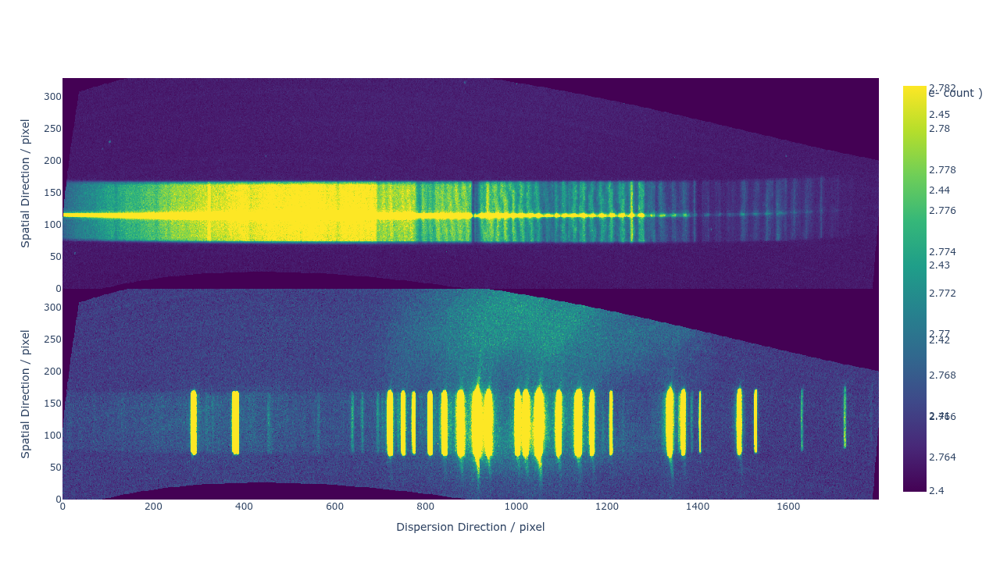

[Thu, 01 Jan 2026 18:10:23] INFO [twodspec.py:3019] Image rectification is applied
[Thu, 01 Jan 2026 18:10:23] INFO [twodspec.py:3029] Arc rectification is applied
[Thu, 01 Jan 2026 18:10:24] INFO [twodspec.py:2036] Correlating the 10-th window.
[Thu, 01 Jan 2026 18:10:24] INFO [twodspec.py:2036] Correlating the 11-th window.
[Thu, 01 Jan 2026 18:10:24] INFO [twodspec.py:2036] Correlating the 12-th window.
[Thu, 01 Jan 2026 18:10:24] INFO [twodspec.py:2036] Correlating the 13-th window.
[Thu, 01 Jan 2026 18:10:24] INFO [twodspec.py:2036] Correlating the 14-th window.
[Thu, 01 Jan 2026 18:10:24] INFO [twodspec.py:2036] Correlating the 15-th window.
[Thu, 01 Jan 2026 18:10:25] INFO [twodspec.py:2036] Correlating the 16-th window.
[Thu, 01 Jan 2026 18:10:25] INFO [twodspec.py:2036] Correlating the 17-th window.
[Thu, 01 Jan 2026 18:10:25] INFO [twodspec.py:2036] Correlating the 18-th window.
[Thu, 01 Jan 2026 18:10:25] INFO [twodspec.py:2036] Correlating the 19-th window.
[Thu, 01 Jan 202

[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 10-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 11-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 12-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 13-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 14-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 15-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 16-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 17-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 18-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 19-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 9-th window.
[Thu, 01 Jan 2026 18:10:36] INFO [twodspec.py:2036] Correlating the 8-th window.
[Thu, 01 Jan 2026 

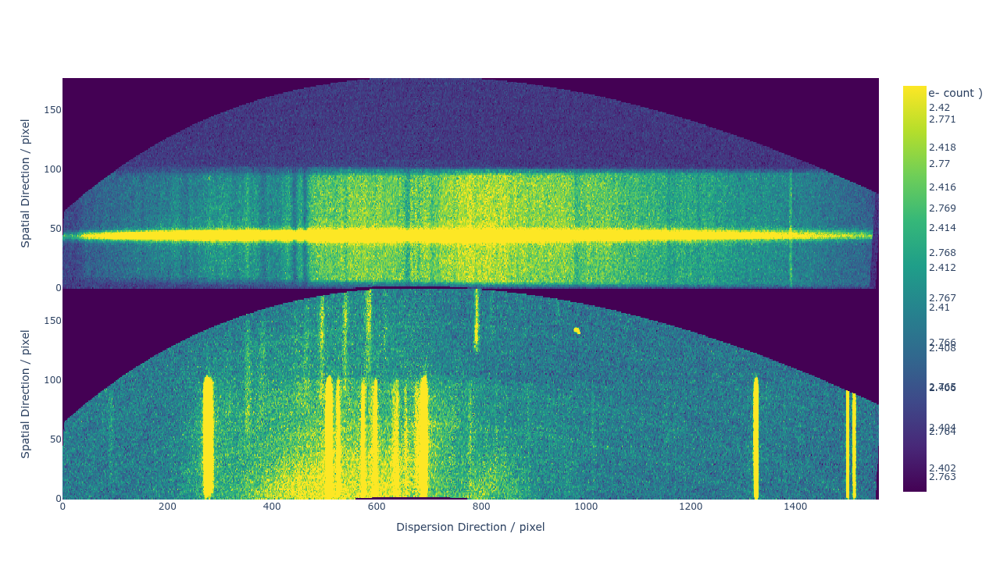

[Thu, 01 Jan 2026 18:10:42] INFO [twodspec.py:3019] Image rectification is applied
[Thu, 01 Jan 2026 18:10:42] INFO [twodspec.py:3029] Arc rectification is applied
[Thu, 01 Jan 2026 18:10:43] INFO [twodspec.py:2036] Correlating the 10-th window.
[Thu, 01 Jan 2026 18:10:43] INFO [twodspec.py:2036] Correlating the 11-th window.
[Thu, 01 Jan 2026 18:10:43] INFO [twodspec.py:2036] Correlating the 12-th window.
[Thu, 01 Jan 2026 18:10:43] INFO [twodspec.py:2036] Correlating the 13-th window.
[Thu, 01 Jan 2026 18:10:44] INFO [twodspec.py:2036] Correlating the 14-th window.
[Thu, 01 Jan 2026 18:10:44] INFO [twodspec.py:2036] Correlating the 15-th window.
[Thu, 01 Jan 2026 18:10:44] INFO [twodspec.py:2036] Correlating the 16-th window.
[Thu, 01 Jan 2026 18:10:44] INFO [twodspec.py:2036] Correlating the 17-th window.
[Thu, 01 Jan 2026 18:10:44] INFO [twodspec.py:2036] Correlating the 18-th window.
[Thu, 01 Jan 2026 18:10:44] INFO [twodspec.py:2036] Correlating the 19-th window.
[Thu, 01 Jan 202

[Thu, 01 Jan 2026 18:10:53] INFO [spectrum_oneD.py:608] arc_header is stored.
[Thu, 01 Jan 2026 18:10:53] INFO [spectrum_oneD.py:608] arc_header is stored.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:293] An numpy array is loaded as data.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:1044] exptime is found to be 80.134.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:1122] Airmass is found to be 1.2081812.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:969] seeing is found to be 1.9388008.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:822] readnoise is found to be 3.5.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:894] gain is found to be 2.3.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:751] spec_size is found to be 2079.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:752] spatial_size is found to be 512.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:760] zmin is set to 2.8273692.
[Thu, 01 Jan 2026 18:10:53] INFO [twodspec.py:761] zmax is set to 4.761477.
[Thu, 01 Jan 2026 18:10:53] IN

In [6]:
#
# Standard frame here
#
standard_light_fits = fits.open("FLOYDS_AT2019mtw_raw_data/standard/"
                                "coj2m002-en12-20210126-0003-e00.fits.fz")[1]

standard_flat_fits = fits.open("FLOYDS_AT2019mtw_raw_data/standard/"
                               "coj2m002-en12-20210126-0004-w00.fits.fz")[1]

standard_arc_fits = fits.open("FLOYDS_AT2019mtw_raw_data/standard/"
                              "coj2m002-en12-20210126-0005-a00.fits.fz")[1]

# Only outputting static plot here, for the equivalent set of dynamic plots, refer to the Science frame in the next cell
standard_twodspec_red, standard_twodspec_blue, standard_twodspec_flat =\
    extract_floyds(standard_light_fits, standard_flat_fits, standard_arc_fits, renderer='png')

In [7]:
#
# Science frame here
#
science_light_fits = fits.open("FLOYDS_AT2019mtw_raw_data/science/"
                               "coj2m002-en12-20200321-0021-e00.fits.fz")[1]

science_flat_fits = fits.open("FLOYDS_AT2019mtw_raw_data/science/"
                              "coj2m002-en12-20200321-0023-w00.fits.fz")[1]

science_arc_fits = fits.open("FLOYDS_AT2019mtw_raw_data/science/"
                             "coj2m002-en12-20200321-0022-a00.fits.fz")[1]

AT2019mtw_twodspec_red, AT2019mtw_twodspec_blue, AT2019mtw_twodspec_flat =\
    extract_floyds(
        science_light_fits,
        science_flat_fits,
        science_arc_fits,
        renderer='notebook')

[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:293] An numpy array is loaded as data.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:1044] exptime is found to be 2700.084.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:1122] Airmass is found to be 1.4742018.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:969] seeing is found to be 0.0.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:822] readnoise is found to be 3.5.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:894] gain is found to be 2.3.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:751] spec_size is found to be 2079.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:752] spatial_size is found to be 512.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:760] zmin is set to 2.7619278.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:761] zmax is set to 2.800717.
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:404] mean value of the image is 590.7739382290164
[Thu, 01 Jan 2026 18:11:01] INFO [twodspec.py:405] median value of the image is 583.0
[Thu, 01

[Thu, 01 Jan 2026 18:11:14] INFO [twodspec.py:3019] Image rectification is applied
[Thu, 01 Jan 2026 18:11:14] INFO [twodspec.py:3029] Arc rectification is applied
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 10-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 11-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 12-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 13-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 14-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 15-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 16-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 17-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 18-th window.
[Thu, 01 Jan 2026 18:11:16] INFO [twodspec.py:2036] Correlating the 19-th window.
[Thu, 01 Jan 202

[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 10-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 11-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 12-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 13-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 14-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 15-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 16-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 17-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 18-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 19-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 9-th window.
[Thu, 01 Jan 2026 18:11:26] INFO [twodspec.py:2036] Correlating the 8-th window.
[Thu, 01 Jan 2026 

[Thu, 01 Jan 2026 18:11:28] INFO [twodspec.py:3019] Image rectification is applied
[Thu, 01 Jan 2026 18:11:28] INFO [twodspec.py:3029] Arc rectification is applied
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 10-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 11-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 12-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 13-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 14-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 15-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 16-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 17-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 18-th window.
[Thu, 01 Jan 2026 18:11:29] INFO [twodspec.py:2036] Correlating the 19-th window.
[Thu, 01 Jan 202

[Thu, 01 Jan 2026 18:11:35] INFO [spectrum_oneD.py:608] arc_header is stored.
[Thu, 01 Jan 2026 18:11:35] INFO [spectrum_oneD.py:608] arc_header is stored.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:293] An numpy array is loaded as data.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:1044] exptime is found to be 40.027.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:1122] Airmass is found to be 1.3582574.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:969] seeing is found to be 0.0.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:822] readnoise is found to be 3.5.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:894] gain is found to be 2.3.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:751] spec_size is found to be 2079.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:752] spatial_size is found to be 512.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:760] zmin is set to 2.7930915.
[Thu, 01 Jan 2026 18:11:35] INFO [twodspec.py:761] zmax is set to 4.4157243.
[Thu, 01 Jan 2026 18:11:35] INFO [t

In [8]:
# Fringe Correction
fringe_correction(AT2019mtw_twodspec_red, AT2019mtw_twodspec_flat)
fringe_correction(standard_twodspec_red, standard_twodspec_flat)

In [9]:
# Start working in 1D
onedspec_blue = calibrate_blue(AT2019mtw_twodspec_blue, standard_twodspec_blue,
                               standard_name)
onedspec_red = calibrate_red(AT2019mtw_twodspec_red, standard_twodspec_red,
                             standard_name, standard_library)

[Thu, 01 Jan 2026 18:11:41] INFO [onedspec.py:268] spectrm1D object is added to spec_id: 0
INFO:OneDSpec:spectrm1D object is added to spec_id: 0
[Thu, 01 Jan 2026 18:11:41] INFO [onedspec.py:1278] Referenced SpectrumOneD of thestandard_spectrum_list to the standard_wavecal.
INFO:OneDSpec:Referenced SpectrumOneD of thestandard_spectrum_list to the standard_wavecal.
[Thu, 01 Jan 2026 18:11:41] INFO [onedspec.py:268] spectrm1D object is added to spec_id: 0
INFO:OneDSpec:spectrm1D object is added to spec_id: 0
[Thu, 01 Jan 2026 18:11:41] INFO [onedspec.py:1253] Referenced SpectrumOneD of thescience_spectrum_list for spec_id: 0.to the corresponding science_wavecal.
INFO:OneDSpec:Referenced SpectrumOneD of thescience_spectrum_list for spec_id: 0.to the corresponding science_wavecal.
[Thu, 01 Jan 2026 18:11:41] INFO [onedspec.py:1783] 10 arc lines are found in science_spectrum_list for spec_id: 0.
INFO:OneDSpec:10 arc lines are found in science_spectrum_list for spec_id: 0.
[Thu, 01 Jan 2026 

[Thu, 01 Jan 2026 18:11:43] INFO [onedspec.py:3019] Wavelength solution is fitted for the science_spectrum_list for spec_id: 0.
INFO:OneDSpec:Wavelength solution is fitted for the science_spectrum_list for spec_id: 0.
[Thu, 01 Jan 2026 18:11:43] INFO [onedspec.py:3032] Attempting to fit wavelength solution for standard_spectrum_list[0].
INFO:OneDSpec:Attempting to fit wavelength solution for standard_spectrum_list[0].
Most inliers: 10, best error: 0.5099: 100%|██████████| 2000/2000 [00:03<00:00, 527.35it/s]


[Thu, 01 Jan 2026 18:11:48] INFO [onedspec.py:3052] Wavelength solution is fitted for the standard_spectrum_list.
INFO:OneDSpec:Wavelength solution is fitted for the standard_spectrum_list.
[Thu, 01 Jan 2026 18:11:48] INFO [onedspec.py:3525] Wavelength calibration is applied for the science_spectrum_list for spec_id: 0.
INFO:OneDSpec:Wavelength calibration is applied for the science_spectrum_list for spec_id: 0.
[Thu, 01 Jan 2026 18:11:48] INFO [onedspec.py:3549] Wavelength calibration is applied for the standard_spectrum_list.
INFO:OneDSpec:Wavelength calibration is applied for the standard_spectrum_list.
[Thu, 01 Jan 2026 18:11:48] WARNING [flux_calibration.py:390] Requested standard star cannot be found, a list of the closest matching names are returned: ['l74546a'].
[Thu, 01 Jan 2026 18:11:48] WARNING [flux_calibration.py:518] The requested standard star cannot be found in the given library, or the library is not specified. ASPIRED is using irafiidscal.
[Thu, 01 Jan 2026 18:11:48] 

[Thu, 01 Jan 2026 18:11:49] INFO [onedspec.py:3839] Inspect sensitivity function.
INFO:OneDSpec:Inspect sensitivity function.
[Thu, 01 Jan 2026 18:11:49] INFO [flux_calibration.py:1582] The exposure time used for flux calibration is 2700.084 seconds.
INFO:OneDSpec:The exposure time used for flux calibration is 2700.084 seconds.
[Thu, 01 Jan 2026 18:11:49] INFO [spectrum_oneD.py:573] standard_header is stored.
INFO:TwoDSpec:standard_header is stored.
[Thu, 01 Jan 2026 18:11:49] INFO [onedspec.py:3933] Flux calibration is applied for the science_spectrum_list for spec_id: 0.
INFO:OneDSpec:Flux calibration is applied for the science_spectrum_list for spec_id: 0.
[Thu, 01 Jan 2026 18:11:49] INFO [flux_calibration.py:1582] The exposure time used for flux calibration is 300.065 seconds.
INFO:OneDSpec:The exposure time used for flux calibration is 300.065 seconds.
[Thu, 01 Jan 2026 18:11:49] INFO [spectrum_oneD.py:573] standard_header is stored.
INFO:TwoDSpec:standard_header is stored.
[Thu, 

[Thu, 01 Jan 2026 18:12:04] INFO [onedspec.py:3019] Wavelength solution is fitted for the science_spectrum_list for spec_id: 0.
INFO:OneDSpec:Wavelength solution is fitted for the science_spectrum_list for spec_id: 0.
[Thu, 01 Jan 2026 18:12:04] INFO [onedspec.py:3032] Attempting to fit wavelength solution for standard_spectrum_list[0].
INFO:OneDSpec:Attempting to fit wavelength solution for standard_spectrum_list[0].
Most inliers: 17, best error: 1.8595: 100%|██████████| 5000/5000 [00:10<00:00, 473.38it/s]


[Thu, 01 Jan 2026 18:12:15] INFO [onedspec.py:3052] Wavelength solution is fitted for the standard_spectrum_list.
INFO:OneDSpec:Wavelength solution is fitted for the standard_spectrum_list.
[Thu, 01 Jan 2026 18:12:15] INFO [onedspec.py:3525] Wavelength calibration is applied for the science_spectrum_list for spec_id: 0.
INFO:OneDSpec:Wavelength calibration is applied for the science_spectrum_list for spec_id: 0.
[Thu, 01 Jan 2026 18:12:15] INFO [onedspec.py:3549] Wavelength calibration is applied for the standard_spectrum_list.
INFO:OneDSpec:Wavelength calibration is applied for the standard_spectrum_list.
[Thu, 01 Jan 2026 18:12:15] INFO [flux_calibration.py:505] The requested standard star l74546a is found in the given library irafredcal.
INFO:OneDSpec:The requested standard star l74546a is found in the given library irafredcal.
[Thu, 01 Jan 2026 18:12:15] INFO [onedspec.py:3605] Loaded standard: l74546a from irafredcal
INFO:OneDSpec:Loaded standard: l74546a from irafredcal
[Thu, 01 

[Thu, 01 Jan 2026 18:12:16] INFO [onedspec.py:3839] Inspect sensitivity function.
INFO:OneDSpec:Inspect sensitivity function.
[Thu, 01 Jan 2026 18:12:16] INFO [flux_calibration.py:1582] The exposure time used for flux calibration is 2700.084 seconds.
INFO:OneDSpec:The exposure time used for flux calibration is 2700.084 seconds.
[Thu, 01 Jan 2026 18:12:16] INFO [spectrum_oneD.py:573] standard_header is stored.
INFO:TwoDSpec:standard_header is stored.
[Thu, 01 Jan 2026 18:12:16] INFO [onedspec.py:3933] Flux calibration is applied for the science_spectrum_list for spec_id: 0.
INFO:OneDSpec:Flux calibration is applied for the science_spectrum_list for spec_id: 0.
[Thu, 01 Jan 2026 18:12:16] INFO [flux_calibration.py:1582] The exposure time used for flux calibration is 300.065 seconds.
INFO:OneDSpec:The exposure time used for flux calibration is 300.065 seconds.
[Thu, 01 Jan 2026 18:12:16] INFO [spectrum_oneD.py:573] standard_header is stored.
INFO:TwoDSpec:standard_header is stored.
[Thu, 

[Thu, 01 Jan 2026 18:12:17] INFO [onedspec.py:4641] Inspecting the telluric absorption profile.
INFO:OneDSpec:Inspecting the telluric absorption profile.
[Thu, 01 Jan 2026 18:12:17] INFO [onedspec.py:4522] telluric_factor is [2.51663027e-15].
INFO:OneDSpec:telluric_factor is [2.51663027e-15].
[Thu, 01 Jan 2026 18:12:17] INFO [onedspec.py:5005] Telluric absorption in the science spectrum is corrected.
INFO:OneDSpec:Telluric absorption in the science spectrum is corrected.
[Thu, 01 Jan 2026 18:12:17] INFO [onedspec.py:5073] Telluric absorption in the standard spectrum is corrected.
INFO:OneDSpec:Telluric absorption in the standard spectrum is corrected.
[Thu, 01 Jan 2026 18:12:17] WARNING [onedspec.py:5187] Atmospheric extinction correction is not configured, The default ORM extinction curve is used.
[Thu, 01 Jan 2026 18:12:17] INFO [onedspec.py:5146] orm extinction correction function is loaded.
INFO:OneDSpec:orm extinction correction function is loaded.
[Thu, 01 Jan 2026 18:12:17] INFO

In [10]:
# Inspect
onedspec_blue.inspect_reduced_spectrum(wave_min=3250,
                                       wave_max=5350,
                                       display=True,
                                       stype='science+standard')

onedspec_red.inspect_reduced_spectrum(wave_min=5100,
                                      wave_max=10000,
                                      display=True,
                                      stype='science+standard')

In [11]:
official_fits = fits.open(
    'FLOYDS_AT2019mtw_raw_data/science/'
    'TAU2020A-010_2092923_fts_20200321_58930/'
    'nttAT2019mtw_fts_20200321_merge_2.0_58930_1_2df_ex.fits')[0]
wave_start = float(official_fits.header['CRVAL1'])
wave_bin = float(official_fits.header['CD1_1'])
spec_length = len(official_fits.data[0][0])
wave = np.linspace(wave_start, wave_start + wave_bin * spec_length,
                   spec_length)

LCO_unit = 1e-20

Text(0.5, 1.0, 'AT 2019 MTW')

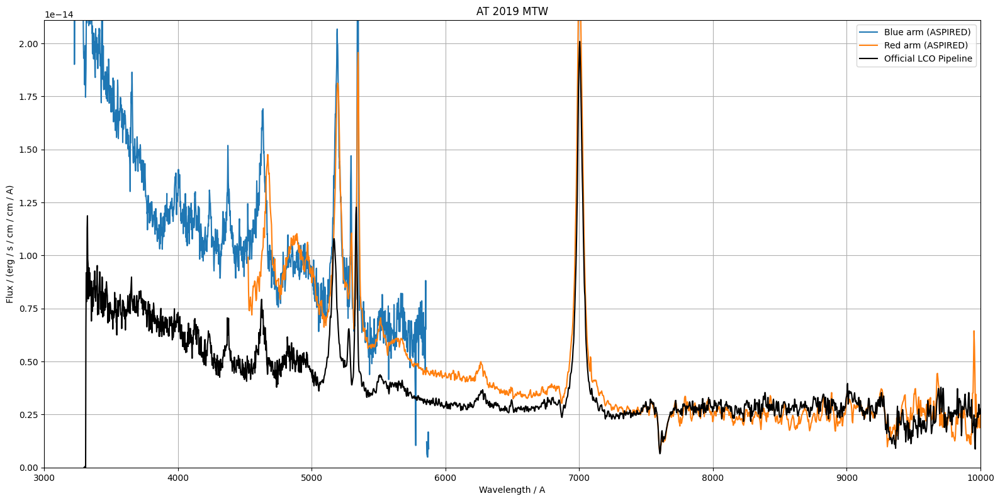

In [12]:
plt.figure(100, figsize=(16, 8))
plt.clf()
plt.plot(onedspec_blue.science_spectrum_list[0].wave_resampled,
         onedspec_blue.science_spectrum_list[0].flux_resampled,
         label='Blue arm (ASPIRED)')
plt.plot(onedspec_red.science_spectrum_list[0].wave_resampled,
         onedspec_red.science_spectrum_list[0].flux_resampled,
         label='Red arm (ASPIRED)')
plt.plot(wave,
         official_fits.data[0][0] * LCO_unit,
         color='black',
         label='Official LCO Pipeline')
plt.xlim(3000., 10000.)
plt.ylim(0, max(official_fits.data[0][0]) * LCO_unit * 1.05)
plt.xlabel('Wavelength / A')
plt.ylabel('Flux / (erg / s / cm / cm / A)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.title('AT 2019 MTW')